# 04b · Answer grounding: a pre-declared follow-up

**Why**
- Notebook 04: grounding the **evidence** phrase is weak on unseen images (within-question AUC 0.544).
- Evidence is short and generic ("a man"): often true of the image but irrelevant to the question.

**Idea**
- Ask the same BLIP-2 ITM model whether the **answer to this question** is grounded:
  `"Question: What is the giraffe in front of? Answer: forest"` vs the image.
- Scored once per distinct answer per question (≈ 2.6 per question) → a few minutes of GPU, no regeneration.

**Pre-declared protocol** (fixed before seeing results, reported either way)
- Primary signal: `qa_itm` = ITM match probability of the question–answer text.
- Same two evaluation protocols as notebook 04: (A) tune on val, test on testdev; (B) 5-fold cross-validation on testdev, folds split by image.

**Runtime:** T4 GPU.

## 1 · Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
REPO_DIR = "/content/drive/MyDrive/cw-mpvr"
%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.utils import load_config, set_seed, gpu_info
from src.errorlog import log_error
from src.gitsync import save_and_push

cfg = load_config()
set_seed(cfg["seed"])
SEED, DATA = cfg["seed"], cfg["paths"]["data"]
print(gpu_info())

Mounted at /content/drive
/content/drive/MyDrive/cw-mpvr
Tesla T4 | 15.6 GB | torch 2.11.0+cu130


## 2 · Let CW-MPVR accept any ITM-style signal
- One-line change in `src/cwmpvr.py`: any signal whose name ends in `itm` is a probability → use its log.
- Results of notebook 04 are unchanged (its signal is still `itm`).

In [ ]:
p = "src/cwmpvr.py"
s = open(p).read()
s = s.replace('if kind == "itm" else v', 'if kind.endswith("itm") else v')
open(p, "w").write(s)

import importlib, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from tqdm.auto import tqdm
import src.paths as P, src.aggregate as A, src.evaluate as E, src.cwmpvr as C
for m in (P, A, E, C):
    importlib.reload(m)

HIGHLIGHT, BASE, LIGHT, INK, MUTED = "#eb6834", "#2a78d6", "#b9b8b2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

read = lambda f: pd.read_csv(f, dtype={"id": str, "imageId": str})
meta = {"eval": read("data/eval_testdev.csv").set_index("id"), "calib": read("data/calib_val.csv").set_index("id")}
GOLD = {s: meta[s]["answer"].map(P.normalize) for s in meta}
IMG = {"eval": f"{DATA}/images/testdev", "calib": f"{DATA}/images/val"}
PTH = {s: A.load_paths(f"results/paths_{s}.jsonl.gz")[1] for s in meta}
print({s: len(PTH[s]) for s in PTH}, "paths")

{'eval': 25000, 'calib': 5000} paths


## 3 · Score question–answer grounding
- Only the ITM model is loaded (~1 B parameters, fp16).
- Each distinct answer of a question is scored once; results saved to `results/` (small CSV) → re-running skips this step.

In [ ]:
from transformers import AutoProcessor, Blip2ForImageTextRetrieval

def score_split(s, itm_proc, itm):
    pairs = PTH[s][["id", "answer"]].drop_duplicates().join(meta[s][["question", "imageId"]], on="id")
    rows = []
    for qid, d in tqdm(pairs.groupby("id", sort=False), desc=s):
        image = Image.open(f"{IMG[s]}/{d.imageId.iloc[0]}.jpg").convert("RGB")
        texts = [f"Question: {d.question.iloc[0]} Answer: {a}" for a in d.answer]
        scores, _ = P.grounding(itm_proc, itm, image, texts)
        rows += [{"id": qid, "answer": a, "qa_itm": v} for a, v in zip(d.answer, scores)]
    return pd.DataFrame(rows)

QA = {}
todo = [s for s in meta if not os.path.exists(f"results/04b_qa_itm_{s}.csv")]
if todo:
    itm_proc = AutoProcessor.from_pretrained(cfg["models"]["itm"])
    itm = Blip2ForImageTextRetrieval.from_pretrained(cfg["models"]["itm"], **P._dtype_kw(torch.float16)).to("cuda").eval()
    for s in todo:
        score_split(s, itm_proc, itm).to_csv(f"results/04b_qa_itm_{s}.csv", index=False)
for s in meta:
    QA[s] = pd.read_csv(f"results/04b_qa_itm_{s}.csv", dtype={"id": str, "answer": str}, keep_default_na=False)
    PTH[s] = PTH[s].merge(QA[s], on=["id", "answer"], how="left")
    print(f"{s}: {len(QA[s]):,} question-answer pairs scored | missing on paths: {PTH[s].qa_itm.isna().sum()}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/554 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.51k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/809 [00:00<?, ?it/s]

eval:   0%|          | 0/2500 [00:00<?, ?it/s]

calib:   0%|          | 0/500 [00:00<?, ?it/s]

eval: 6,578 question-answer pairs scored | missing on paths: 0
calib: 1,299 question-answer pairs scored | missing on paths: 0


## 4 · Is answer grounding a better signal?
- Same within-question test as notebooks 02 and 04: among one question's paths, are correct ones scored higher?
- AUC 0.5 = no better than chance.

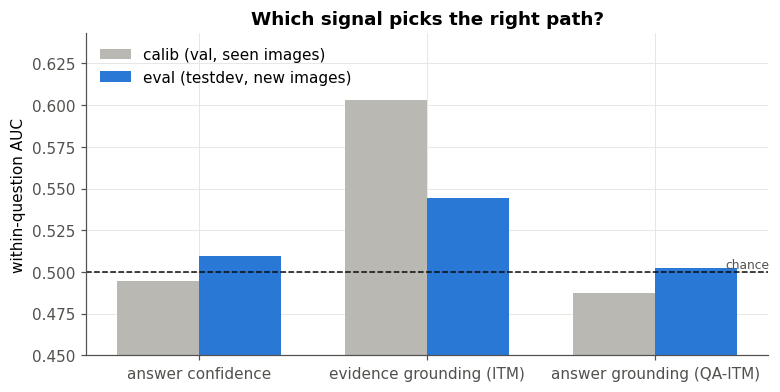

,"calib (val, seen images)","eval (testdev, new images)"
answer confidence,0.4943,0.5095
evidence grounding (ITM),0.6030,0.5442
answer grounding (QA-ITM),0.4875,0.5024


In [ ]:
def within_auc(s, sig):
    p = PTH[s].assign(ok=PTH[s].answer.values == GOLD[s].reindex(PTH[s].id).values)
    vals = []
    for _, d in p.groupby("id"):
        ok = d.ok.values
        if ok.all() or not ok.any():
            continue
        v = d[sig].values
        diff = v[ok][:, None] - v[~ok][None, :]
        vals.append((diff > 0).mean() + 0.5 * (diff == 0).mean())
    return float(np.mean(vals))

SIG = {"lp_mean": "answer confidence", "itm": "evidence grounding (ITM)", "qa_itm": "answer grounding (QA-ITM)"}
auc = pd.DataFrame({s: {SIG[k]: within_auc(s, k) for k in SIG} for s in ("calib", "eval")}).round(4)
auc.columns = ["calib (val, seen images)", "eval (testdev, new images)"]
auc.to_csv("results/04b_within_auc.csv")

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(auc)); w = 0.36
ax.bar(x - w/2, auc.iloc[:, 0], w, color=LIGHT, label=auc.columns[0])
ax.bar(x + w/2, auc.iloc[:, 1], w, color=BASE, label=auc.columns[1])
ax.axhline(0.5, color=INK, linewidth=1, linestyle="--")
ax.text(len(auc) - 0.5, 0.502, "chance", ha="right", fontsize=8, color=MUTED)
ax.set_xticks(x, auc.index); ax.set_ylabel("within-question AUC")
lo = min(0.45, auc.values.min() - 0.02); ax.set_ylim(lo, auc.values.max() + 0.04)
ax.set_title("Which signal picks the right path?"); ax.legend(loc="upper left")
plt.savefig("figures/04b_signal_auc.png"); plt.show()
auc

## 5 · Protocol A: tune on val, test on testdev
- Exactly as notebook 04, with answer grounding in place of evidence grounding.

In [ ]:
BETAS  = [0, 0.25, 0.5, 1, 2, 4, 8]
GAMMAS = [0, 0.25, 0.5, 1, 2, 4, 8, 16]

def protocol_a(grounding, betas=BETAS, gammas=GAMMAS):
    b = C.select(C.grid_search(PTH["calib"], GOLD["calib"], betas, gammas, grounding))
    pred = C.cw_mpvr(PTH["eval"], b.beta, b.gamma, grounding)["answer"]
    return float(b.beta), float(b.gamma), pred.reindex(GOLD["eval"].index).eq(GOLD["eval"])

res_a = {}
for name, g, bs, gs in [("CW-MPVR (evidence ITM)", "itm", BETAS, GAMMAS), ("CW-MPVR (QA-ITM)", "qa_itm", BETAS, GAMMAS),
                        ("Grounding-only (QA-ITM)", "qa_itm", [0], GAMMAS)]:
    b, g_, ok = protocol_a(g, bs, gs)
    res_a[name] = {"beta": b, "gamma": g_, "eval accuracy": round(100 * ok.mean(), 2)}
pd.DataFrame(res_a).T

,beta,gamma,eval accuracy
CW-MPVR (evidence ITM),2.0,8.00,39.60
CW-MPVR (QA-ITM),2.0,0.25,40.88
Grounding-only (QA-ITM),0.0,0.50,40.84


## 6 · Protocol B: cross-validation on testdev
- 5 folds split by image; weights tuned on 4 folds, applied to the 5th → every prediction is out-of-fold.
- Same folds for every method → paired comparisons are fair.

In [ ]:
from sklearn.model_selection import GroupKFold

ids = GOLD["eval"].index.values
groups = meta["eval"].loc[ids, "imageId"].values
FOLDS = list(GroupKFold(5).split(ids, groups=groups))
pe = PTH["eval"]

def cross_validate(grounding, betas, gammas):
    pred, chosen = pd.Series(index=ids, dtype=object), []
    for tr, te in FOLDS:
        b = C.select(C.grid_search(pe[pe.id.isin(ids[tr])], GOLD["eval"].loc[ids[tr]], betas, gammas, grounding))
        chosen.append((float(b.beta), float(b.gamma)))
        pred.loc[ids[te]] = C.cw_mpvr(pe[pe.id.isin(ids[te])], b.beta, b.gamma, grounding)["answer"].reindex(ids[te]).values
    return pred, chosen

CV = {
    "Answer-only (CV)":            ("itm", BETAS, [0]),
    "Evidence grounding-only (CV)": ("itm", [0], GAMMAS),
    "CW-MPVR evidence (CV)":       ("itm", BETAS, GAMMAS),
    "QA grounding-only (CV)":      ("qa_itm", [0], GAMMAS),
    "CW-MPVR QA (CV)":             ("qa_itm", BETAS, GAMMAS),
}
cv_pred, cv_chosen = pd.DataFrame(index=ids), {}
for name, (g, bs, gs) in CV.items():
    cv_pred[name], cv_chosen[name] = cross_validate(g, bs, gs)
cv_pred["Majority vote"] = A.majority(pe)["answer"].reindex(ids)
cv_pred["Greedy"] = A.load_paths("results/paths_eval.jsonl.gz")[0].set_index("id")["greedy"].reindex(ids)
cv_pred.index.name = "id"
cv_pred.to_csv("results/04b_cv_predictions_eval.csv")

cv_correct = cv_pred.eq(GOLD["eval"].reindex(ids), axis=0)
cv_table = E.accuracy_table(cv_correct, groups, SEED)
cv_table.to_csv("results/04b_cv_accuracy.csv")
for k, v in cv_chosen.items():
    print(f"{k:30s} (β, γ) per fold: {v}")
cv_table

Answer-only (CV)               (β, γ) per fold: [(1.0, 0.0), (1.0, 0.0), (1.0, 0.0), (0.5, 0.0), (0.5, 0.0)]
Evidence grounding-only (CV)   (β, γ) per fold: [(0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, 0.25)]
CW-MPVR evidence (CV)          (β, γ) per fold: [(2.0, 0.25), (2.0, 0.25), (2.0, 0.25), (2.0, 0.25), (2.0, 0.25)]
QA grounding-only (CV)         (β, γ) per fold: [(0.0, 0.5), (0.0, 0.25), (0.0, 0.5), (0.0, 0.25), (0.0, 0.0)]
CW-MPVR QA (CV)                (β, γ) per fold: [(1.0, 0.0), (0.5, 0.25), (0.5, 0.25), (0.5, 0.25), (0.5, 0.25)]


,accuracy,ci_low,ci_high
Answer-only (CV),41.04,38.92,43.13
Evidence grounding-only (CV),41.04,39.02,43.07
CW-MPVR evidence (CV),41.32,39.24,43.40
QA grounding-only (CV),40.60,38.54,42.67
CW-MPVR QA (CV),41.08,39.03,43.15
Majority vote,40.68,38.62,42.74
Greedy,40.20,38.16,42.23


## 7 · Significance (cross-validated)

In [ ]:
def compare(a, b):
    bs = E.paired_bootstrap(cv_correct[a], cv_correct[b], groups, seed=SEED)
    return {"A": a, "B": b, "A − B (pts)": 100 * bs["diff"], **E.mcnemar(cv_correct[a], cv_correct[b]),
            "CI low": 100 * bs["ci_lo"], "CI high": 100 * bs["ci_hi"], "p_boot": bs["p_boot"]}

pairs = [("CW-MPVR QA (CV)", "Majority vote"), ("CW-MPVR QA (CV)", "Greedy"), ("CW-MPVR QA (CV)", "Answer-only (CV)"),
         ("CW-MPVR QA (CV)", "CW-MPVR evidence (CV)"), ("QA grounding-only (CV)", "Answer-only (CV)")]
cv_tests = pd.DataFrame([compare(a, b) for a, b in pairs])
cv_tests.to_csv("results/04b_cv_tests.csv", index=False)
cv_tests.round(4)

,A,B,A − B (pts),only_A,only_B,p_mcnemar,CI low,CI high,p_boot
0,CW-MPVR QA (CV),Majority vote,0.40,26,16,0.1641,-0.1167,0.9310,0.1564
1,CW-MPVR QA (CV),Greedy,0.88,98,76,0.1111,-0.2137,2.0259,0.1376
2,CW-MPVR QA (CV),Answer-only (CV),0.04,8,7,1.0000,-0.2709,0.3329,0.9028
3,CW-MPVR QA (CV),CW-MPVR evidence (CV),-0.24,17,23,0.4296,-0.7510,0.2676,0.3900
4,QA grounding-only (CV),Answer-only (CV),-0.44,16,27,0.1263,-0.9660,0.0822,0.1244


## 8 · Save to GitHub

In [9]:
# Print every results table from this notebook as text (to copy into the chat)
import glob
for f in sorted(glob.glob("results/04b_*.csv")):
    print(f"\n=== {f}")
    print(pd.read_csv(f).to_string(index=False))

Streaming output truncated to the last 5000 lines.
  2017243                                           coat 0.042127
  2017243                                            hat 0.033431
  2017243                                          shirt 0.062560
  2017243                                          horse 0.336168
  2017243                                         jacket 0.029091
  2017243                                           cows 0.065845
  2017243                                          scarf 0.452785
 20240864                                          table 0.040087
 20240864                                          chair 0.121634
201482038                                             no 0.016277
201482038                                            yes 0.018761
201682342                                        to left 0.079639
201682342                                       to right 0.079210
201498046                                           desk 0.132402
201947832                

In [11]:
for f in ["results/04b_cv_accuracy.csv", "results/04b_cv_tests.csv"]:
    print(f"\n=== {f}")
    print(pd.read_csv(f).round(4).to_string(index=False))
print("\n=== Protocol A (tune on val)")
print(pd.DataFrame(res_a).T)
print("\n=== chosen (β, γ) per fold")
for k, v in cv_chosen.items():
    print(f"{k:30s} {v}")


=== results/04b_cv_accuracy.csv
                  Unnamed: 0  accuracy  ci_low  ci_high
            Answer-only (CV)     41.04   38.92    43.13
Evidence grounding-only (CV)     41.04   39.02    43.07
       CW-MPVR evidence (CV)     41.32   39.24    43.40
      QA grounding-only (CV)     40.60   38.54    42.67
             CW-MPVR QA (CV)     41.08   39.03    43.15
               Majority vote     40.68   38.62    42.74
                      Greedy     40.20   38.16    42.23

=== results/04b_cv_tests.csv
                     A                     B  A − B (pts)  only_A  only_B  p_mcnemar  CI low  CI high  p_boot
       CW-MPVR QA (CV)         Majority vote         0.40      26      16     0.1641 -0.1167   0.9310  0.1564
       CW-MPVR QA (CV)                Greedy         0.88      98      76     0.1111 -0.2137   2.0259  0.1376
       CW-MPVR QA (CV)      Answer-only (CV)         0.04       8       7     1.0000 -0.2709   0.3329  0.9028
       CW-MPVR QA (CV) CW-MPVR evidence (CV)     

In [ ]:
save_and_push("notebooks/04b_answer_grounding.ipynb", "Add answer-grounding follow-up with cross-validated evaluation")

## Observations

- **Answer grounding carries no signal**: within-question AUC 0.488 (val) and 0.502 (testdev), i.e. chance, even on images seen in pretraining.
- Reason: the ITM head was trained on descriptive captions; it can confirm *what is in the image* ("man, tree, giraffe") but cannot judge whether an *answer to a question* is correct.
- Cross-validated on testdev: CW-MPVR with QA grounding 41.1% ≈ answer-only 41.0% (+0.04 pts, McNemar p = 1.0); evidence grounding remains best (41.3%).
- Protocol A with QA grounding (40.9%) beats Protocol A with evidence grounding (39.6%), because QA grounding is not inflated on seen images, so tuning on val does not over-weight it; further evidence for the contamination effect.
- Conclusion: the pre-declared follow-up is **negative**; evidence grounding stays the method's grounding signal.